# KNN e métricas de classificação

Vamos classificar o mesmo **breast-cancer.csv** da aula de regressão logística, com as 30 características e os rótulos **0 = benigno, 1 = maligno**.

Primeiro construiremos o KNN com **NumPy**. Depois compararemos com **scikit-learn**. Pandas lê o CSV e apresenta tabelas, e Matplotlib desenha os gráficos. As fórmulas aparecem antes do código, que recebe explicação linha a linha.

**Execução:** abra o notebook na pasta `KNN`, selecione o Python do ambiente `venv` e execute as células em ordem. O CSV já está nesta pasta. Os exemplos usam diretamente os formatos e valores desta base para manter o código simples.

**Exemplos visuais:** veremos uma consulta ligada aos seus vizinhos e, ao final, um experimento com duas luas para visualizar o efeito de `k` e comparar com regressão logística.

## 1. Importações

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**Explicação linha a linha**

1. Importa NumPy com o apelido `np`, para vetores, matrizes e operações numéricas.
2. Importa pandas como `pd`, para ler o CSV e apresentar tabelas; o algoritmo será NumPy.
3. Importa a interface de gráficos do Matplotlib como `plt`.

## 2. Ler o dataset

Cada linha é uma amostra. Removemos o identificador `id`, a resposta `diagnosis` e a coluna vazia `Unnamed: 32`. As 30 colunas restantes são medidas celulares. A resposta fica separada das entradas para que o modelo não receba a própria resposta ao prever.

In [2]:
dados = pd.read_csv("breast-cancer.csv")
X = dados.drop(columns=["id", "diagnosis", "Unnamed: 32"]).to_numpy(dtype=float)
y = dados["diagnosis"].map({"B": 0, "M": 1}).to_numpy()
print("X:", X.shape, "| y:", y.shape)
dados.head()

X: (569, 30) | y: (569,)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


**Explicação linha a linha**

1. Lê o CSV da pasta do notebook em uma tabela.
2. Remove as três colunas e transforma as medidas em uma matriz de números reais.
3. Converte benigno em 0 e maligno em 1, formando o vetor de respostas.
4. Mostra 569 amostras com 30 entradas e 569 respostas.
5. Exibe as primeiras cinco linhas da tabela.

## 3. Separar treino e teste

Embaralhamos os índices e reservamos 80% para treino: $\lfloor0{,}8\times569\rfloor=455$ linhas. As outras 114 ficam no teste. Usamos os mesmos índices para selecionar entradas e respostas, preservando cada par.

A semente 42 reproduz a divisão da aula de regressão logística. O teste fica reservado para avaliar o modelo depois da escolha de `k`.

In [3]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(y))
cut = int(0.8 * len(y))
train_indices = indices[:cut]
test_indices = indices[cut:]
X_train, X_test = X[train_indices], X[test_indices]
y_train, y_test = y[train_indices], y[test_indices]
print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Treino: (455, 30) | Teste: (114, 30)


**Explicação linha a linha**

1. Cria um gerador local com semente 42; reexecutar a célula recria o mesmo sorteio.
2. Embaralha todos os índices das 569 amostras sem repetição.
3. Calcula 455, descartando a parte decimal do número positivo.
4. Reserva os primeiros 455 índices para o conjunto de treino externo.
5. Reserva os 114 índices restantes para o teste final.
6. Seleciona as entradas dos dois conjuntos usando índices sem sobreposição.
7. Aplica os mesmos índices às respostas, preservando o alinhamento com as entradas.
8. Mostra as dimensões da divisão externa, idêntica à da aula de regressão logística.

## 4. O que é o KNN?

**KNN** significa *K-Nearest Neighbors*, ou K-vizinhos mais próximos. O algoritmo guarda os exemplos de treino e seus rótulos. Para classificar uma nova amostra:

1. Calcula sua distância a cada exemplo de treino.
2. Seleciona os `k` exemplos mais próximos.
3. Escolhe a classe com mais votos entre esses vizinhos.

A hipótese é que exemplos próximos nas características tenham respostas semelhantes. Diferentemente da regressão logística, o KNN não ajusta pesos por gradiente. `k` é uma configuração que escolheremos na validação.

## 5. De onde vem a distância euclidiana?

Em duas dimensões, as diferenças de coordenadas formam os catetos de um triângulo retângulo. Pelo teorema de Pitágoras:

$$d(a,b)^2=(a_1-b_1)^2+(a_2-b_2)^2.$$

Com $p$ características, estendemos a soma a todas as coordenadas:

$$d(a,b)=\sqrt{\sum_{j=1}^{p}(a_j-b_j)^2}.$$

Subtraímos as coordenadas, elevamos as diferenças ao quadrado, somamos e extraímos a raiz. Os quadrados impedem que diferenças com sinais contrários se cancelem. Por exemplo, entre `(0, 0)` e `(3, 4)`, a distância é $\sqrt{9+16}=5$.

In [4]:
a = np.array([0.0, 0.0])
b = np.array([3.0, 4.0])
diferencas = a - b
distancia = np.sqrt(np.sum(diferencas ** 2))
print("Diferenças:", diferencas, "| Distância:", distancia)

Diferenças: [-3. -4.] | Distância: 5.0


**Explicação linha a linha**

1. Cria um ponto com duas coordenadas reais.
2. Cria outro ponto, deslocado 3 unidades na primeira coordenada e 4 na segunda.
3. Produz o vetor [-3, -4], uma diferença por coordenada.
4. Eleva cada diferença ao quadrado, soma 9 + 16 e extrai a raiz: distância 5.
5. Exibe o vetor intermediário e o resultado para ligar o código a Pitágoras.

## 6. Padronização

Características com valores grandes podem dominar a distância. Para compará-las em unidades de desvio padrão, calculamos uma média e um desvio por coluna do treino:

$$\mu_j=\frac1m\sum_{i=1}^{m}x_{ij},\qquad s_j=\sqrt{\frac1m\sum_{i=1}^{m}(x_{ij}-\mu_j)^2}.$$

Subtraímos a média para centralizar e dividimos pelo desvio para ajustar a escala:

$$x'_{ij}=\frac{x_{ij}-\mu_j}{s_j}.$$

O NumPy usa divisor $m$ no desvio padrão (`ddof=0`). Validação e teste usam **as mesmas médias e desvios do ajuste**, sem recalculá-los. As colunas desta base têm desvio diferente de zero nos conjuntos usados abaixo.

In [5]:
def padronizar(X_ajuste, X_consulta):
    media = X_ajuste.mean(axis=0)
    desvio = X_ajuste.std(axis=0)
    ajuste_scaled = (X_ajuste - media) / desvio
    consulta_scaled = (X_consulta - media) / desvio
    return ajuste_scaled, consulta_scaled

**Explicação linha a linha**

1. Define uma função que prepara as referências e as consultas usando a mesma escala.
2. Calcula uma média por coluna das referências.
3. Calcula um desvio padrão por coluna das referências.
4. Padroniza as referências. O NumPy aplica as estatísticas de cada coluna a todas as linhas.
5. Padroniza as consultas com as estatísticas das referências.
6. Retorna as duas matrizes transformadas.

## 7. Calcular as distâncias com NumPy

`X_ref` contém as referências, com uma amostra por linha. `consulta` é um vetor com as características de uma única amostra. Subtrair esse vetor da matriz calcula as diferenças para todas as referências.

In [6]:
def distancias_euclidianas(X_ref, consulta):
    diferencas = X_ref - consulta
    quadrados = diferencas ** 2
    somas = quadrados.sum(axis=1)
    return np.sqrt(somas)

**Explicação linha a linha**

1. Define o cálculo de uma distância por linha da matriz de referência.
2. Subtrai o vetor de consulta de cada linha; o resultado tem formato `(m, p)`.
3. Eleva as diferenças ao quadrado, elemento a elemento; o formato continua `(m, p)`.
4. Soma pelas colunas de cada linha; `axis=1` produz um vetor `(m,)`.
5. Extrai a raiz de cada soma, devolvendo as distâncias da consulta a todas as referências.

## 8. Votação dos vizinhos

Ordenamos as distâncias e pegamos os primeiros `k` índices. Como os rótulos são 0 e 1, somá-los conta os vizinhos malignos. Dividir por `k` fornece sua proporção:

$$\widehat p_1(x)=\frac1k\sum_{i\in\mathcal N_k(x)}y_i.$$

`N` representa o conjunto de vizinhos selecionados. Para os votos `[0, 1, 1]`, a proporção maligna é $2/3$. Escolhemos a classe 1 quando essa proporção é maior que 0,5.

A votação também pode ser entendida como a escolha que comete menos erros entre os vizinhos: se uma classe tem $v$ votos, escolhê-la contraria $k-v$ rótulos. Mais votos significam menos erros locais.

Usaremos `k` ímpar para evitar empate entre as duas classes. A proporção de votos é uma estimativa local, sem garantia de corresponder à probabilidade real em outros dados.

In [7]:
def prever_knn(X_ref, y_ref, X_consultas, k=5):
    probabilidades = np.zeros(len(X_consultas))
    for i, consulta in enumerate(X_consultas):
        distancias = distancias_euclidianas(X_ref, consulta)
        vizinhos = np.argsort(distancias)[:k]
        probabilidades[i] = y_ref[vizinhos].mean()
    previsoes = (probabilidades > 0.5).astype(int)
    return previsoes, probabilidades

**Explicação linha a linha**

1. Recebe referências, rótulos, consultas e a quantidade de vizinhos.
2. Cria um vetor para guardar uma proporção maligna por consulta.
3. Percorre cada consulta e sua posição no vetor de resultados.
4. Calcula as distâncias da consulta a todas as referências.
5. Ordena os índices pelas distâncias e seleciona os primeiros `k`.
6. Calcula a média dos rótulos selecionados, que é a fração de malignos.
7. Transforma as proporções em classes 0 ou 1. Se houver empate, a regra escolhe 0.
8. Retorna as classes e as proporções, na ordem das consultas.

## 9. Exemplo pequeno

A consulta é `(0, 0)`. As referências abaixo têm distâncias 1, 2, 3 e 4. Com `k=3`, os rótulos selecionados são `[0, 1, 1]`: a previsão deve ser classe 1, com fração maligna de 2/3.

In [8]:
X_exemplo = np.array([[1.0, 0.0], [0.0, 2.0], [3.0, 0.0], [0.0, 4.0]])
y_exemplo = np.array([0, 1, 1, 0])
consulta_exemplo = np.array([[0.0, 0.0]])
pred_exemplo, prob_exemplo = prever_knn(X_exemplo, y_exemplo, consulta_exemplo, k=3)
print("Distâncias:", distancias_euclidianas(X_exemplo, consulta_exemplo[0]))
print("Classe:", pred_exemplo, "| Fração maligna:", prob_exemplo)

Distâncias: [1. 2. 3. 4.]
Classe: [1] | Fração maligna: [0.66666667]


**Explicação linha a linha**

1. Cria quatro referências com duas características cada.
2. Associa um rótulo a cada referência.
3. Cria uma matriz com uma consulta na origem.
4. Classifica a consulta usando os três vizinhos mais próximos.
5. Mostra as distâncias calculadas: 1, 2, 3 e 4.
6. Mostra a classe prevista e a fração de votos malignos.

### Os três vizinhos no gráfico

Vamos desenhar o exemplo anterior. A estrela representa a consulta na origem. As linhas tracejadas ligam a consulta aos três vizinhos que votaram. As cores indicam as classes, e as letras identificam as quatro referências.

Este é um exemplo artificial com duas características. O modelo principal do Breast Cancer continua usando as 30 medidas.

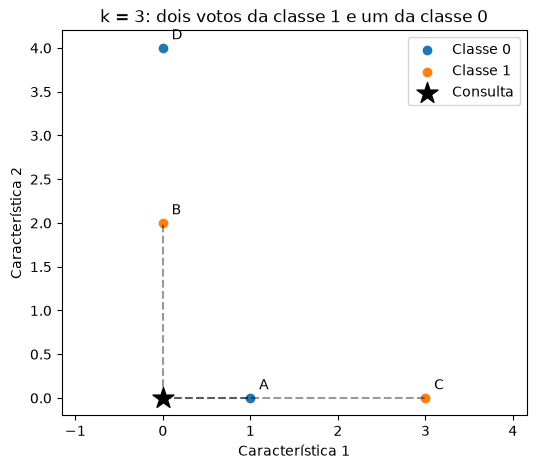

In [9]:
distancias_exemplo = distancias_euclidianas(X_exemplo, consulta_exemplo[0])
vizinhos_exemplo = np.argsort(distancias_exemplo)[:3]
plt.figure(figsize=(6, 5))
plt.scatter(X_exemplo[y_exemplo == 0, 0], X_exemplo[y_exemplo == 0, 1], color="tab:blue", label="Classe 0")
plt.scatter(X_exemplo[y_exemplo == 1, 0], X_exemplo[y_exemplo == 1, 1], color="tab:orange", label="Classe 1")
plt.scatter(0, 0, marker="*", s=250, color="black", label="Consulta", zorder=3)
for i in vizinhos_exemplo:
    plt.plot([0, X_exemplo[i, 0]], [0, X_exemplo[i, 1]], "k--", alpha=0.4)
for i, nome in enumerate(["A", "B", "C", "D"]):
    plt.text(X_exemplo[i, 0] + 0.1, X_exemplo[i, 1] + 0.1, nome)
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.title("k = 3: dois votos da classe 1 e um da classe 0")
plt.axis("equal")
plt.legend()
plt.show()

**Explicação linha a linha**

1. Calcula as quatro distâncias à consulta do exemplo.
2. Seleciona os índices das três menores distâncias.
3. Cria a figura para o exemplo de duas características.
4. Desenha as referências da classe 0, usando a primeira coluna no eixo horizontal e a segunda no vertical.
5. Desenha as referências da classe 1 com outra cor.
6. Desenha a consulta como uma estrela. `zorder=3` a mantém à frente das linhas.
7. Percorre os três vizinhos selecionados.
8. Liga a origem a cada vizinho com uma linha preta tracejada e semitransparente.
9. Percorre os nomes das quatro referências e seus índices.
10. Escreve a letra ao lado de cada referência, com um pequeno deslocamento.
11. Nomeia o eixo horizontal.
12. Nomeia o eixo vertical.
13. Relaciona o desenho ao resultado da votação.
14. Usa a mesma escala nos dois eixos para preservar a geometria das distâncias.
15. Identifica as cores das classes e a estrela da consulta.
16. Exibe o gráfico.

## 10. Escolher `k` na validação

Com `k` pequeno, a decisão é muito local e pode ser sensível a ruído. Com `k` grande, ela fica mais suavizada, mas pode misturar regiões diferentes.

Separamos as 455 linhas de treino em **364 referências de ajuste e 91 consultas de validação**. Só as referências determinam a escala. Escolheremos o `k` com maior acurácia de validação:

$$\operatorname{Acurácia}=\frac{\text{número de acertos}}{\text{número de consultas}}.$$

`np.mean(previsoes == respostas)` calcula essa fração: cada comparação correta vale 1 e cada incorreta vale 0. Em empate, a lista crescente de candidatos e `argmax` escolhem o menor `k`.

In [10]:
rng_val = np.random.default_rng(123)
indices_val = rng_val.permutation(len(y_train))
cut_val = int(0.8 * len(y_train))
fit_indices, val_indices = indices_val[:cut_val], indices_val[cut_val:]
X_fit, X_val = X_train[fit_indices], X_train[val_indices]
y_fit, y_val = y_train[fit_indices], y_train[val_indices]
X_fit_scaled, X_val_scaled = padronizar(X_fit, X_val)
ks = [1, 3, 5, 7, 9, 11, 15, 21]
acuracias_val = []
for k in ks:
    pred_val, prob_val = prever_knn(X_fit_scaled, y_fit, X_val_scaled, k)
    acuracias_val.append(np.mean(pred_val == y_val))
melhor_k = ks[np.argmax(acuracias_val)]
print(pd.DataFrame({"k": ks, "Acurácia validação": acuracias_val}))
print("k escolhido:", melhor_k)

    k  Acurácia validação
0   1            0.956044
1   3            0.967033
2   5            0.945055
3   7            0.956044
4   9            0.956044
5  11            0.956044
6  15            0.956044
7  21            0.956044
k escolhido: 3


**Explicação linha a linha**

1. Cria um gerador para reproduzir a divisão interna do treino.
2. Embaralha apenas os índices das 455 linhas de treino.
3. Reserva 364 linhas para ajuste e deixa 91 para validação.
4. Separa os índices nos dois grupos.
5. Seleciona as entradas dos dois grupos.
6. Seleciona os rótulos correspondentes.
7. Padroniza usando somente as estatísticas das referências de ajuste.
8. Define os candidatos ao número de vizinhos.
9. Cria a lista que guardará as acurácias.
10. Experimenta cada candidato na mesma validação.
11. Produz as previsões de validação para o `k` atual.
12. Calcula e guarda a acurácia desse candidato.
13. Pega o candidato na posição de maior acurácia.
14. Exibe os resultados de todos os candidatos.
15. Mostra o número de vizinhos escolhido sem consultar o teste.

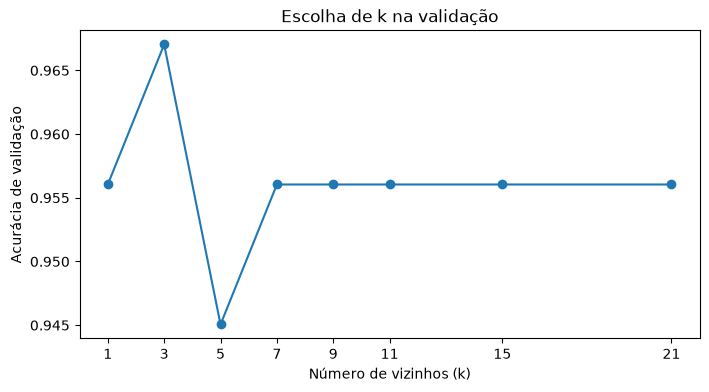

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(ks, acuracias_val, "o-")
plt.xlabel("Número de vizinhos (k)")
plt.ylabel("Acurácia de validação")
plt.xticks(ks)
plt.title("Escolha de k na validação")
plt.show()

**Explicação linha a linha**

1. Cria a figura para visualizar os candidatos.
2. Desenha a acurácia de validação de cada `k`, usando pontos ligados por linhas.
3. Nomeia o eixo horizontal.
4. Nomeia o eixo vertical.
5. Mostra os valores de `k` experimentados.
6. Adiciona o título do gráfico.
7. Exibe a figura.

## 11. Prever o teste

Fixado `k`, usamos as **455 linhas de treino** como referências finais. Recalculamos a escala nesse treino completo e aplicamos a mesma transformação às 114 consultas de teste.

In [12]:
X_train_scaled, X_test_scaled = padronizar(X_train, X_test)
pred_numpy, prob_numpy = prever_knn(X_train_scaled, y_train, X_test_scaled, melhor_k)
print("Primeiras previsões:", pred_numpy[:10])
print("Respostas reais:", y_test[:10])

Primeiras previsões: [0 1 0 0 1 1 1 0 0 1]
Respostas reais: [0 1 0 0 1 1 1 0 0 1]


**Explicação linha a linha**

1. Prepara o treino final e o teste usando as estatísticas das 455 referências.
2. Classifica o teste usando o número de vizinhos escolhido na validação.
3. Mostra as classes previstas para as primeiras dez amostras de teste.
4. Mostra as respostas correspondentes para uma primeira comparação.

## 12. Métricas de classificação

### Matriz de confusão

A classe positiva é **maligno = 1**. Cada previsão pertence a uma destas quatro contagens:

| Classe real / prevista | Benigno (0) | Maligno (1) |
|---|---|---|
| Benigno (0) | TN: benigno correto | FP: benigno classificado como maligno |
| Maligno (1) | FN: maligno classificado como benigno | TP: maligno correto |

As **linhas são reais** e as **colunas são previstas**. A diagonal reúne os acertos. O total é $n=TN+FP+FN+TP$.

Vamos acompanhar um exemplo com dez decisões: **TN=4, FP=1, FN=3 e TP=2**.

### Acurácia

Entre todas as decisões, quantas estão corretas? Somamos os acertos da diagonal e dividimos pelo total:

$$\operatorname{Acurácia}=\frac{TP+TN}{n}=\frac{2+4}{10}=60\%.$$

Acurácia não distingue FP de FN. Em uma base com 990 negativos e 10 positivos, prever tudo como negativo dá 99% de acurácia, sem encontrar nenhum positivo.

### Precisão

Entre as previsões positivas, quantas eram positivas reais? A coluna dos previstos positivos tem $TP+FP$ amostras, das quais TP são acertos:

$$P=\frac{TP}{TP+FP}=\frac2{2+1}\approx66{,}67\%.$$

Ela descreve a confiabilidade dos alertas. Falsos positivos reduzem essa fração.

### Recall ou sensibilidade

Entre os positivos reais, quantos encontramos? A linha dos positivos reais tem $TP+FN$ amostras, das quais TP foram detectadas:

$$R=\frac{TP}{TP+FN}=\frac2{2+3}=40\%.$$

Falsos negativos reduzem o recall. Precisão e recall usam grupos diferentes no denominador: previstos positivos e positivos reais, respectivamente.

### F1-score

O F1 combina precisão e recall pela **média harmônica**: calculamos a média dos inversos e invertemos o resultado.

$$F_1=\frac2{1/P+1/R}=\frac{2PR}{P+R}.$$

Substituindo $P=TP/(TP+FP)$ e $R=TP/(TP+FN)$ e simplificando os fatores comuns:

$$F_1=\frac{2TP}{(TP+FP)+(TP+FN)}=\frac{2TP}{2TP+FP+FN}.$$

No exemplo, $F_1=4/(4+1+3)=50\%$. A média harmônica fica baixa quando uma das duas métricas está baixa. O F1 não inclui TN e não substitui a leitura dos tipos de erro.

### Especificidade

É o recall da classe negativa: entre os benignos reais, quantos reconhecemos?

$$S=\frac{TN}{TN+FP}=\frac4{4+1}=80\%.$$

### Implementação direta

Uma comparação como `(y_real == 1) & (y_pred == 1)` identifica os verdadeiros positivos. `np.sum` conta os resultados verdadeiros. Depois aplicamos as fórmulas acima.

As divisões abaixo usam diretamente as contagens dos exemplos desta aula, cujos denominadores são positivos. Fora desses exemplos, uma razão com denominador zero é indefinida.

In [13]:
def metricas_binarias(y_real, y_pred):
    tn = np.sum((y_real == 0) & (y_pred == 0))
    fp = np.sum((y_real == 0) & (y_pred == 1))
    fn = np.sum((y_real == 1) & (y_pred == 0))
    tp = np.sum((y_real == 1) & (y_pred == 1))
    acuracia = (tp + tn) / len(y_real)
    precisao = tp / (tp + fp)
    recall = tp / (tp + fn)
    especificidade = tn / (tn + fp)
    f1 = 2 * tp / (2 * tp + fp + fn)
    metricas = {"Acurácia": acuracia, "Precisão": precisao, "Recall": recall, "Especificidade": especificidade, "F1": f1}
    matriz = np.array([[tn, fp], [fn, tp]])
    return metricas, matriz

**Explicação linha a linha**

1. Define uma função para calcular as métricas e a matriz de confusão.
2. Conta benignos classificados como benignos. `&` combina as duas condições.
3. Conta benignos classificados como malignos.
4. Conta malignos classificados como benignos.
5. Conta malignos classificados como malignos.
6. Divide o total de acertos pelo número de amostras.
7. Divide os positivos corretos pelo total previsto positivo.
8. Divide os positivos encontrados pelo total real positivo.
9. Divide os negativos corretos pelo total real negativo.
10. Calcula o F1 diretamente pelas contagens.
11. Guarda os resultados em um dicionário, relacionando cada nome ao seu valor.
12. Organiza as contagens com linhas reais e colunas previstas.
13. Retorna os resumos e as contagens usadas para calculá-los.

### Exemplo com dez decisões

Vamos reproduzir a matriz `[[4, 1], [3, 2]]` usando dois vetores pequenos. Cada posição compara a resposta real e a prevista da mesma amostra.

In [14]:
y_real_demo = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])
y_pred_demo = np.array([0, 0, 0, 0, 1, 0, 0, 0, 1, 1])
metricas_demo, matriz_demo = metricas_binarias(y_real_demo, y_pred_demo)
print(matriz_demo)
print(pd.Series(metricas_demo).round(4))

[[4 1]
 [3 2]]
Acurácia          0.6000
Precisão          0.6667
Recall            0.4000
Especificidade    0.8000
F1                0.5000
dtype: float64


**Explicação linha a linha**

1. Cria cinco negativos e cinco positivos reais.
2. Cria as dez previsões: quatro TN, um FP, três FN e dois TP.
3. Calcula as contagens e métricas do exemplo.
4. Mostra a matriz de confusão.
5. Mostra os valores: acurácia 0,6, precisão 0,6667, recall 0,4, especificidade 0,8 e F1 0,5.

### Avaliar o KNN

Aplicamos a mesma função às previsões do teste. A tabela mostra as métricas e a matriz permite identificar os tipos de erro.

In [15]:
metricas_numpy, cm_numpy = metricas_binarias(y_test, pred_numpy)
print(pd.Series(metricas_numpy).round(4))
pd.DataFrame(cm_numpy, index=["Real benigno", "Real maligno"], columns=["Previsto benigno", "Previsto maligno"])

Acurácia          0.9737
Precisão          0.9535
Recall            0.9762
Especificidade    0.9722
F1                0.9647
dtype: float64


,Previsto benigno,Previsto maligno
Real benigno,70,2
Real maligno,1,41


**Explicação linha a linha**

1. Compara as previsões do KNN às respostas reais do teste.
2. Mostra as métricas, arredondando apenas a exibição.
3. Exibe a matriz com nomes que deixam clara a ordem das classes.

## 13. Comparar com scikit-learn

Agora usamos o `KNeighborsClassifier` com o mesmo `k`, distância euclidiana e votos uniformes. Ele recebe **as mesmas matrizes já padronizadas com NumPy**, para manter a comparação simples.

`fit` guarda as referências e seus rótulos. `predict` busca os vizinhos e decide as classes. Continuamos usando nossa função de métricas para comparar as duas implementações.

In [16]:
from sklearn.neighbors import KNeighborsClassifier
modelo_sklearn = KNeighborsClassifier(n_neighbors=melhor_k, weights="uniform", metric="euclidean", algorithm="brute")
modelo_sklearn.fit(X_train_scaled, y_train)
pred_sklearn = modelo_sklearn.predict(X_test_scaled)
metricas_sklearn, cm_sklearn = metricas_binarias(y_test, pred_sklearn)
comparacao = pd.DataFrame([metricas_numpy, metricas_sklearn], index=["NumPy", "scikit-learn"])
print(comparacao.round(4))
print("Previsões diferentes:", np.sum(pred_numpy != pred_sklearn))

              Acurácia  Precisão  Recall  Especificidade      F1
NumPy           0.9737    0.9535  0.9762          0.9722  0.9647
scikit-learn    0.9737    0.9535  0.9762          0.9722  0.9647
Previsões diferentes: 0


**Explicação linha a linha**

1. Importa o classificador KNN pronto.
2. Configura o mesmo número de vizinhos, voto uniforme, distância euclidiana e busca exaustiva.
3. Guarda as referências já padronizadas e seus rótulos.
4. Classifica as consultas de teste na mesma escala.
5. Calcula as métricas das previsões da biblioteca.
6. Organiza os resultados em uma tabela, com uma linha por implementação.
7. Mostra a comparação das métricas.
8. Conta quantas decisões foram diferentes entre as implementações.

## 14. Resultado e interpretação

Com estas divisões, a validação escolhe **`k=3`**. No teste, as duas implementações acertam **111 de 114 amostras (97,37%)** e produzem as mesmas decisões.

A matriz `[[70, 2], [1, 41]]` contém **dois falsos positivos e um falso negativo**. Precisão = 41/43 = 95,35%, recall = 41/42 = 97,62%, especificidade = 70/72 = 97,22% e F1 = 82/85 = 96,47%.

Esses números descrevem esta divisão dos dados. O teste serve para avaliar a escolha feita na validação, sem alterar `k` depois de olhar seu resultado.

## 15. KNN e regressão logística

| Aspecto | KNN | Regressão logística |
|---|---|---|
| Ajuste | Guarda referências e rótulos | Aprende intercepto e pesos |
| Previsão | Distâncias e votos dos vizinhos | Combinação linear, sigmoide e limiar |
| Fronteira | Pode formar regiões irregulares | Linear nas entradas usadas |
| Pontos fortes | Simples de entender e inspecionar | Modelo compacto e previsão rápida |
| Limitações | Depende da escala e guarda os exemplos | Pode precisar transformar entradas para representar relações mais complexas |

O KNN precisa comparar cada consulta às referências. Mais exemplos aumentam o trabalho de previsão. Características irrelevantes, ruído e muitas dimensões também podem prejudicar a noção de proximidade.

## 16. Experimento visual: duas luas

Um dos pontos fortes do `knn_aula` é mostrar **as regiões de decisão**: para cada posição do gráfico, pintamos a classe prevista pelo modelo. Vamos usar essa ideia em um pequeno experimento complementar.

`make_moons` cria duas classes em formato de luas. Cada ponto tem apenas duas características, então podemos desenhar sua posição e a região prevista. Essas classes são **0 e 1 de um exemplo artificial**, sem significado de diagnóstico.

Mantemos a preparação conhecida: separar treino e teste com NumPy e calcular a escala só no treino. Os valores `k=1`, `15` e `61` serão usados para visualizar o efeito da vizinhança. Fixamos `k=15` para a comparação com logística **antes de consultar o teste**, sem escolher o melhor gráfico pelo resultado de teste.

In [17]:
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
X_luas, y_luas = make_moons(n_samples=300, noise=0.25, random_state=42)
rng_luas = np.random.default_rng(42)
indices_luas = rng_luas.permutation(len(y_luas))
corte_luas = int(0.8 * len(y_luas))
treino_luas, teste_luas = indices_luas[:corte_luas], indices_luas[corte_luas:]
X_luas_train, X_luas_test = X_luas[treino_luas], X_luas[teste_luas]
y_luas_train, y_luas_test = y_luas[treino_luas], y_luas[teste_luas]
X_luas_train_scaled, X_luas_test_scaled = padronizar(X_luas_train, X_luas_test)

**Explicação linha a linha**

1. Importa o gerador do exemplo artificial de duas luas.
2. Importa a regressão logística que compararemos ao KNN.
3. Cria 300 pontos, com ruído e semente fixa para reproduzir o desenho.
4. Cria um gerador local para a divisão desse experimento.
5. Embaralha as posições dos 300 pontos sem repetição.
6. Calcula 240 pontos de treino, deixando 60 para teste.
7. Separa os índices em dois blocos.
8. Seleciona as entradas de treino e teste.
9. Seleciona as respostas com os mesmos índices das entradas.
10. Usa a função NumPy já construída para preparar os dois conjuntos com a escala de treino.

### Como desenhar uma fronteira de decisão?

Criamos uma **grade de posições** que cobre a região do treino. O modelo classifica cada posição, e o gráfico pinta o fundo conforme essa previsão. A separação entre as cores representa a fronteira.

`meshgrid` combina posições horizontais e verticais. `ravel` transforma as matrizes da grade em vetores, e `column_stack` organiza os pares de coordenadas como consultas. Após prever, `reshape` recoloca as classes no formato da grade. A função abaixo serve tanto para KNN quanto para regressão logística.

In [18]:
def desenhar_fronteira(modelo, X_ref, y_ref, ax, titulo):
    eixo_x = np.linspace(X_ref[:, 0].min() - 0.5, X_ref[:, 0].max() + 0.5, 120)
    eixo_y = np.linspace(X_ref[:, 1].min() - 0.5, X_ref[:, 1].max() + 0.5, 120)
    xx, yy = np.meshgrid(eixo_x, eixo_y)
    grade = np.column_stack([xx.ravel(), yy.ravel()])
    classes_grade = modelo.predict(grade).reshape(xx.shape)
    ax.contourf(xx, yy, classes_grade, levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.25)
    ax.scatter(X_ref[:, 0], X_ref[:, 1], c=y_ref, cmap="coolwarm", vmin=0, vmax=1, s=18)
    ax.set_title(titulo)
    ax.set_xlabel("Característica 1 padronizada")
    ax.set_ylabel("Característica 2 padronizada")
    ax.set_aspect("equal")

**Explicação linha a linha**

1. Define uma função que desenha a região prevista por um modelo e os pontos de treino.
2. Cria 120 posições horizontais entre o menor e o maior valor do treino, acrescentando uma margem.
3. Cria 120 posições verticais com a mesma ideia.
4. Combina os dois eixos em matrizes com 120 × 120 posições.
5. Organiza as 14.400 posições como uma matriz de consultas, com duas colunas.
6. Classifica todas as posições e devolve as classes ao formato da grade.
7. Pinta as regiões das classes 0 e 1, com transparência. Os limites separam os dois rótulos inteiros.
8. Desenha os pontos de treino com a mesma escala de cores: azul para 0 e vermelho para 1.
9. Adiciona o título recebido pela função.
10. Nomeia o eixo horizontal.
11. Nomeia o eixo vertical.
12. Mantém a mesma escala geométrica nos dois eixos.

### O efeito de `k` nas regiões

Cada painel usa o mesmo treino, a mesma escala e a mesma distância. Só alteramos o número de vizinhos. Os pontos sobrepostos são as referências de treino. Esses gráficos ilustram o comportamento dos modelos, sem usar o teste para selecionar `k`.

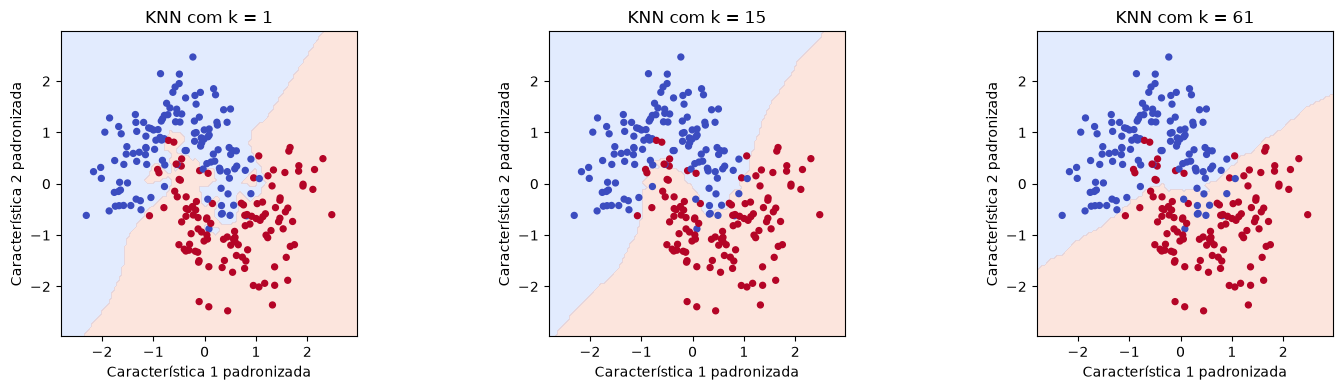

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, [1, 15, 61]):
    modelo_visual = KNeighborsClassifier(n_neighbors=k)
    modelo_visual.fit(X_luas_train_scaled, y_luas_train)
    desenhar_fronteira(modelo_visual, X_luas_train_scaled, y_luas_train, ax, f"KNN com k = {k}")
plt.tight_layout()
plt.show()

**Explicação linha a linha**

1. Cria três painéis lado a lado.
2. Associa cada painel a um número de vizinhos.
3. Cria um KNN com o número de vizinhos do painel.
4. Guarda as mesmas referências e respostas em cada modelo.
5. Desenha a região de decisão usando a função explicada acima.
6. Ajusta os espaços entre os painéis e seus rótulos.
7. Exibe a comparação das três vizinhanças.

**Como interpretar:** com `k=1`, pequenos detalhes dos pontos podem criar regiões irregulares. Com mais vizinhos, a votação suaviza a região prevista e pode perder detalhes. São tendências, não garantias de que um `k` seja melhor em qualquer base.

### Regressão logística e KNN nas mesmas luas

A regressão logística usa $z=b+w_1x_1+w_2x_2$ e $p=1/(1+e^{-z})$. No limiar 0,5, a fronteira satisfaz $z=0$: uma reta nessas duas entradas. O KNN pode acompanhar uma separação curva pela votação local.

Vamos comparar a logística e o KNN com `k=15`, fixado no início deste experimento. Ambos usam o mesmo treino padronizado e o mesmo teste. A acurácia será uma descrição desta execução, não uma conclusão de que um algoritmo sempre supera o outro.

Regressão logística — acurácia de teste: 0.833
KNN com k = 15 — acurácia de teste: 0.95


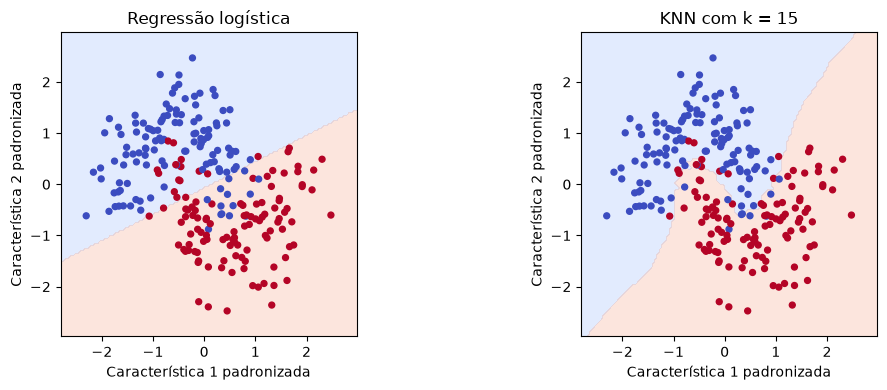

In [20]:
modelo_logistica_luas = LogisticRegression()
modelo_knn_luas = KNeighborsClassifier(n_neighbors=15)
modelos_luas = [modelo_logistica_luas, modelo_knn_luas]
nomes_luas = ["Regressão logística", "KNN com k = 15"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, modelo, nome in zip(axes, modelos_luas, nomes_luas):
    modelo.fit(X_luas_train_scaled, y_luas_train)
    pred_luas = modelo.predict(X_luas_test_scaled)
    acuracia_luas = np.mean(pred_luas == y_luas_test)
    print(nome, "— acurácia de teste:", round(acuracia_luas, 3))
    desenhar_fronteira(modelo, X_luas_train_scaled, y_luas_train, ax, nome)
plt.tight_layout()
plt.show()

**Explicação linha a linha**

1. Cria a regressão logística com as configurações padrão da biblioteca.
2. Cria o KNN com o `k` fixado antes da avaliação.
3. Agrupa os dois modelos para executar o mesmo procedimento.
4. Define os nomes dos painéis.
5. Cria um painel para cada modelo.
6. Percorre juntos o painel, o modelo e seu nome.
7. Ajusta cada modelo usando somente o treino.
8. Classifica as 60 amostras de teste já padronizadas.
9. Calcula a fração de acertos no teste com NumPy.
10. Mostra a acurácia do modelo, arredondada para três casas decimais.
11. Desenha a região prevista e os pontos de treino para o mesmo modelo avaliado.
12. Ajusta as margens e a separação entre os dois painéis.
13. Exibe as fronteiras da logística e do KNN.

Nesta execução, a logística acertou **50 de 60 amostras (83,33%)** e o KNN com `k=15` acertou **57 de 60 (95%)**. A região curva ajuda a explicar essa diferença neste exemplo.

**Para discutir:** a diferença vem da forma que cada modelo consegue representar com estas entradas. Acrescentar características polinomiais à logística permitiria fronteiras curvas no espaço original. O KNN oferece flexibilidade local, mas depende da escala, da distância e das referências armazenadas. Os resultados do exemplo das luas não substituem os resultados do Breast Cancer.

## 17. Exercícios

1. Calcule a classe do exemplo pequeno para `k=1`, `k=3` e `k=4`.
2. Explique por que precisão e recall podem ser diferentes.
3. O que acontece quando `k` é igual ao número de referências?
4. Por que a padronização deve usar apenas as estatísticas do ajuste?
5. Nos gráficos das luas, como `k` altera os detalhes da fronteira?
6. Por que a regressão logística com duas entradas originais produz uma reta como fronteira?

## Referências

- [Scikit-learn: vizinhos mais próximos](https://scikit-learn.org/stable/modules/neighbors.html).
- [Scikit-learn: KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html).
- [UCI: Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic).

Mantivemos `B=0` e `M=1`, como na aula de regressão logística. O carregador `load_breast_cancer` usa a convenção oposta.